<a href="https://colab.research.google.com/github/Oli-via123/AI-ML-Practice-and-Projects/blob/main/AI%20and%20ML%20Assignment/%20Week_5_NN_Assignment_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. Import
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__) # This is to check the TensorFlow version
tf.random.set_seed(234)   # This is to set a random seed for reproducibility

TensorFlow version: 2.21.0


In [2]:
# Here is the sample data consisting of just 10 samples
# X is the feature with each sample having record of study hours and sleep hours
# For example first observation is [1, 4] i.e, study hours = 1, sleep hours = 4
# second observation is [2, 5], i.e, study hours = 2, sleep hours = 5 and so on

X = np.array([[1, 4], [2, 5], [3, 6], [4, 5], [5, 7],
              [6, 6], [7, 8], [8, 7], [9, 8], [10, 7]], dtype="float32")

# This is the label for all 10 samples
# y is one value per sample: 0 means fail and 1 means pass
# first-four samples failed(0) and last six sample passed(1)
y = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1], dtype="float32")


### Complete the following task

In [3]:
# 2. Build the mode Build the model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(1, activation='sigmoid', input_shape=(2,))
    ])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [4]:
# 3. Inspect the model parameters with summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3 (12.00 B)

 Trainable params: 3 (12.00 B)

 Non-trainable params: 0 (0.00 B)

In [5]:
# 4. Compile
model.compile(optimizer='adam',
              loss='binary_crossentropy',
                            metrics=['accuracy'])

In [6]:
# 5. Train
history = model.fit(X, y, epochs=200, verbose=0)
print("Training done")


Training done


In [7]:
# 6. Predict: 6 hours study, 7 hours sleep
new_student = np.array([[6, 7]], dtype="float32")
prediction = model.predict(new_student)

print("Prediction:", prediction)
print("Chance of passing:", prediction[0][0])

if prediction[0][0] > 0.5:
  print("Result: Pass")
else:
   print("Result: Fail")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Prediction: [[0.99949527]]
Chance of passing: 0.99949527
Result: Pass


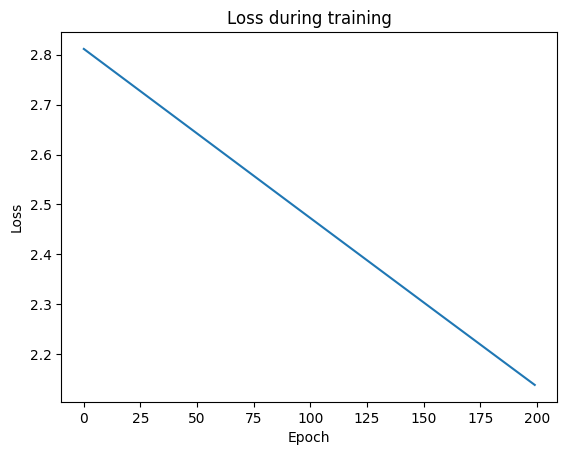

In [9]:
# 7. Loss plot
plt.plot(history.history['loss'])
plt.title("Loss during training")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()